# Real data

**A test on real data is only worth something if you can run it again on exactly the same numbers, and if the model saw nothing after the forecast date.**

TimeGym's own test series are generated, so it holds their answer key: the best forecast anyone could make from the same history. Real data has no answer key, only what actually happened, and even that can move: data providers revise past prices and recompute their adjustments. This chapter builds `get_stock`, an optional helper that downloads a ticker's daily history from Yahoo Finance and freezes it in a snapshot file, so an experiment reruns offline on the same numbers.

Then we run the simplest real-data test: hide the last year of a classic series, monthly airline passengers, forecast it from the years before with three simple rules, and compare each forecast with what actually happened. Nothing in this notebook uses the network.

**Development notebook.** The collapsed cells are the library code; expand one to edit it, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp data.real

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'pyproject.toml').is_file() and (p / 'timegym').is_dir())
plt.style.use('default')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110,
    'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})

## Download once, rerun from the snapshot: `get_stock`

The module needs only pandas and the standard library. It imports yfinance only when it actually has to download.

In [3]:
#| export data.real
from __future__ import annotations

from collections.abc import Sequence
from io import StringIO
import json
from pathlib import Path
from tempfile import NamedTemporaryFile

import pandas as pd


`get_stock(ticker, columns="Close")` returns one ticker's full daily history as a DataFrame, even for a single column, with the columns in the order you asked for. Install `timegym[market-data]` before the first download. Three settings decide what you get:

- `auto_adjust=True`, the default, asks for prices adjusted for splits and dividends, so a 2-for-1 split doesn't look like a crash. `False` gives the raw prices. They are different targets: choose one before you start.
- `cache_path="data/msft.json"` saves the download as a snapshot file. Every later call with the same ticker and `auto_adjust` reads that file instead, with no network and no yfinance, and can ask for any of its columns.
- `refresh=True` downloads again and replaces the snapshot. Without it, a snapshot made with other settings, or a damaged one, raises an error instead of quietly downloading something new.

Missing values are kept as they are, not filled or dropped.

In [4]:
#| export data.real
def _validate_stock_history(history: pd.DataFrame) -> None:
    if not isinstance(history, pd.DataFrame) or history.empty:
        raise ValueError("Stock history must be a nonempty pandas DataFrame")
    if not isinstance(history.index, pd.DatetimeIndex) or history.index.hasnans:
        raise ValueError("Stock history must have a DatetimeIndex without NaT")
    if not history.index.is_unique or not history.index.is_monotonic_increasing:
        raise ValueError("Stock history dates must be unique and increasing")
    if not history.columns.is_unique:
        raise ValueError("Stock history columns must be unique")


def get_stock(
    ticker: str,
    columns: str | Sequence[str] = "Close",
    *,
    auto_adjust: bool = True,
    cache_path: str | Path | None = None,
    refresh: bool = False,
) -> pd.DataFrame:
    """Read one ticker's daily history as a DataFrame in requested column order.

    Without a matching cache this fetches period='max' from Yahoo Finance via
    the optional timegym[market-data] dependency. auto_adjust=True, the default,
    requests the provider's adjusted OHLC including Close, so splits and dividends
    do not appear as jumps; False keeps the unadjusted fields. Missing values are
    preserved, not filled or dropped.

    cache_path is a JSON snapshot file containing full history, ticker and
    adjustment metadata. A cache hit needs neither yfinance nor the network.
    Mismatched or invalid caches raise; refresh=True explicitly fetches and
    replaces a snapshot after successful validation. Provider/network errors
    propagate and empty histories raise ValueError. Snapshots freeze retrieved
    data, not the historical information available at each forecast origin.
    """
    if not isinstance(ticker, str) or not ticker.strip():
        raise ValueError("ticker must be a nonempty string")
    ticker = ticker.strip().upper()
    if not isinstance(auto_adjust, bool) or not isinstance(refresh, bool):
        raise TypeError("auto_adjust and refresh must be bools")
    if isinstance(columns, str):
        selected = [columns]
    elif isinstance(columns, Sequence):
        selected = list(columns)
    else:
        raise TypeError("columns must be a column name or a sequence of names")
    if (
        not selected
        or any(not isinstance(name, str) or not name for name in selected)
        or len(set(selected)) != len(selected)
    ):
        raise ValueError("columns must contain unique nonempty strings")
    path = None if cache_path is None else Path(cache_path)
    metadata = {"schema_version": 1, "ticker": ticker, "auto_adjust": auto_adjust}
    cached = path is not None and path.exists() and not refresh
    if cached:
        try:
            payload = json.loads(path.read_text(encoding="utf-8"))
            if payload["metadata"] != metadata:
                raise ValueError("ticker or auto_adjust does not match")
            history = pd.read_json(
                StringIO(json.dumps(payload["history"])), orient="table"
            )
            _validate_stock_history(history)
        except (ValueError, TypeError, KeyError) as exc:
            raise ValueError(f"Invalid stock cache at {path}: {exc}") from exc
    else:
        try:
            import yfinance
        except ImportError as exc:
            raise ImportError(
                "Install timegym[market-data] to fetch stock history"
            ) from exc
        history = yfinance.Ticker(ticker).history(period="max", auto_adjust=auto_adjust)
        _validate_stock_history(history)
    missing = [name for name in selected if name not in history.columns]
    if missing:
        raise ValueError(f"Stock history is missing requested columns: {missing}")
    if path is not None and not cached:
        payload = {
            "metadata": metadata,
            "history": json.loads(
                history.to_json(orient="table", date_unit="ns", double_precision=15)
            ),
        }
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = None
        try:
            with NamedTemporaryFile(
                mode="w",
                encoding="utf-8",
                dir=path.parent,
                prefix=f".{path.name}.",
                suffix=".tmp",
                delete=False,
            ) as handle:
                temporary = Path(handle.name)
                json.dump(payload, handle, allow_nan=False)
                handle.write("\n")
            temporary.replace(path)
        finally:
            if temporary is not None:
                temporary.unlink(missing_ok=True)
    result = history.loc[:, selected].copy()
    result.index = result.index.as_unit("ns")
    return result


## A snapshot in action

So that this notebook never touches the network, a stand-in plays Yahoo Finance: it serves five made-up trading days for a made-up ticker, DEMO, and counts how often it is asked. Because `get_stock` imports the provider only when it needs to download, putting the stand-in in Python's module table under the name `yfinance` is enough.

In [5]:
import sys
from tempfile import TemporaryDirectory
from types import SimpleNamespace

made_up_prices = pd.DataFrame({'Close': [101.0, 102.5, 101.8, 103.2, 104.0],
                               'Volume': [1200, 1500, 900, 1100, 1300]},
                              index=pd.bdate_range('2024-03-04', periods=5, name='Date'))
downloads = []


def download(period, auto_adjust):
    downloads.append(auto_adjust)
    return made_up_prices.copy()


stand_in = SimpleNamespace(Ticker=lambda ticker: SimpleNamespace(history=download))

Three calls: the first downloads and saves the snapshot; the second runs with no provider at all and asks for two columns; the third asks for unadjusted prices from the adjusted snapshot.

In [6]:
previous = sys.modules.get('yfinance')  # the real yfinance, if it was already imported
with TemporaryDirectory() as folder:
    snapshot = Path(folder) / 'demo-adjusted.json'
    try:
        sys.modules['yfinance'] = stand_in
        first = get_stock('DEMO', cache_path=snapshot)  # downloads, then saves the snapshot
        sys.modules['yfinance'] = None  # from here on, importing yfinance fails
        again = get_stock('DEMO', ['Volume', 'Close'], cache_path=snapshot)  # read from the file
        try:
            get_stock('DEMO', cache_path=snapshot, auto_adjust=False)
        except ValueError as error:
            refusal = str(error).replace(str(snapshot), snapshot.name)
        else:
            raise AssertionError('A snapshot with other settings must be refused.')
    finally:
        sys.modules.pop('yfinance')
        if previous is not None:
            sys.modules['yfinance'] = previous

assert len(downloads) == 1  # one download: the second call read the file
pd.testing.assert_frame_equal(again[['Close']], first, check_freq=False)  # the same numbers back
print(f'Downloads: {len(downloads)}. Second call, from the snapshot alone:')
display(again)
print(f'Third call: {refusal}')

Downloads: 1. Second call, from the snapshot alone:


,Volume,Close
Date,,
2024-03-04,1200,101.0
2024-03-05,1500,102.5
2024-03-06,900,101.8
2024-03-07,1100,103.2
2024-03-08,1300,104.0


Third call: Invalid stock cache at demo-adjusted.json: ticker or auto_adjust does not match


The stand-in was asked once. The second call found the snapshot, read it with no provider available, and served a different choice of columns from the same file. The third call was refused instead of being answered with a quiet new download, so an experiment never switches data without saying so. Keep the snapshot with the experiment's results; `refresh=True` is the deliberate way to replace it.

## One hidden year, three simple rules

Now a real series. AirPassengers counts international airline passengers each month, in thousands, from 1949 to 1960; the file and its [source record](../experiments/data/README.md) ship with TimeGym. We give the models the ten years up to December 1958 and hide 1959. Each rule sees only that history and the dates to forecast:

- **Last value**: every month of 1959 equals December 1958.
- **Historical mean**: every month equals the average of the ten years.
- **Same month last year**: each month repeats its value from 1958.

In [7]:
from timegym import NaiveForecaster, Pipeline

raw = pd.read_csv(ROOT / 'experiments/data/AirPassengers.csv')
series = pd.DataFrame({'passengers': raw['value'].to_numpy(float)},
                      index=pd.period_range('1949-01', periods=len(raw), freq='M'))
history, hidden = series.iloc[:120], series.iloc[120:132]  # up to December 1958, and all of 1959
rules = {'Last value': NaiveForecaster('last'),
         'Historical mean': NaiveForecaster('mean'),
         'Same month last year': NaiveForecaster('seasonal', period=12)}
forecasts = {name: Pipeline(rule).predict(history, hidden.index)  # history and dates only
             for name, rule in rules.items()}

actual = hidden['passengers'].to_numpy()
misses = pd.DataFrame({name: forecast.point[:, 0] - actual for name, forecast in forecasts.items()})
summary = pd.DataFrame({'Average miss (thousands)': misses.abs().mean().round(1),
                        'Months forecast too low': (misses < 0).sum()})
growth = actual.sum() / history['passengers'].iloc[-12:].sum() - 1
assert summary['Average miss (thousands)'].idxmin() == 'Same month last year'  # repeating the cycle wins
assert (summary['Months forecast too low'] == 12).all()  # yet every rule is too low in every month
print(f'Passengers in 1959 were {growth:.0%} above 1958.')
display(summary)

Passengers in 1959 were 12% above 1958.


,Average miss (thousands),Months forecast too low
Last value,91.3,12
Historical mean,182.4,12
Same month last year,47.3,12


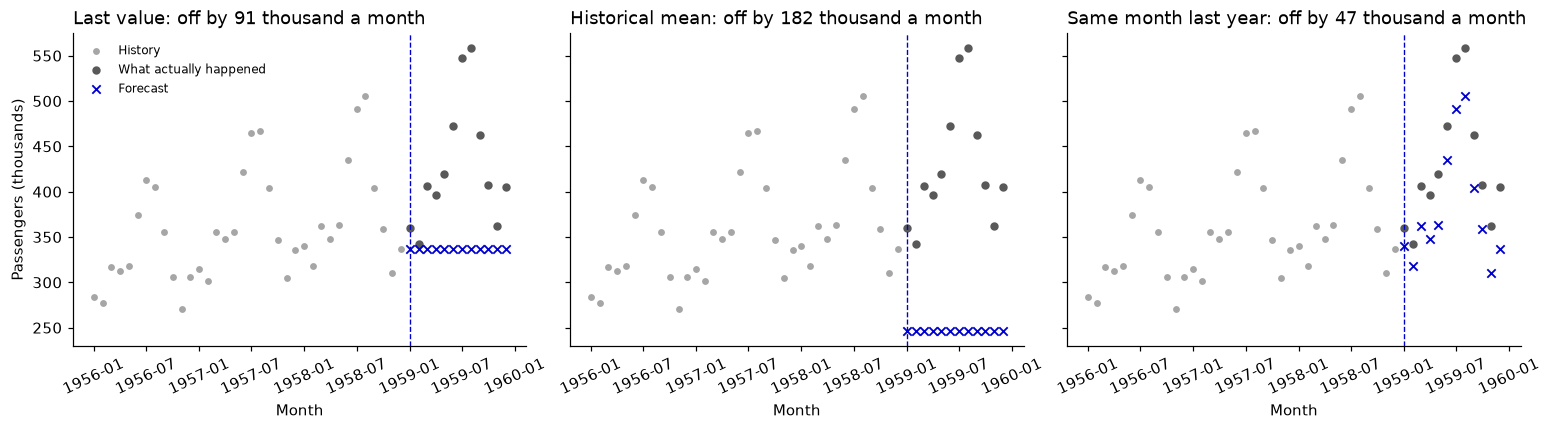

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True, layout='constrained')
recent = history.iloc[-36:]
for ax, (name, forecast) in zip(axes, forecasts.items()):
    ax.scatter(recent.index.to_timestamp(), recent['passengers'], s=12, color='0.65', label='History')
    ax.scatter(hidden.index.to_timestamp(), actual, s=20, color='0.35', label='What actually happened')
    ax.scatter(forecast.index.to_timestamp(), forecast.point[:, 0], s=30, marker='x',
               color='#0000CC', linewidths=1.2, label='Forecast')
    ax.axvline(hidden.index[0].to_timestamp(), color='#0000CC', ls='--', lw=0.9)
    ax.set(title=f"{name}: off by {summary.loc[name, 'Average miss (thousands)']:.0f} thousand a month", xlabel='Month')
    ax.tick_params(axis='x', labelrotation=25)
axes[0].set_ylabel('Passengers (thousands)')
axes[0].legend(fontsize=8, loc='upper left')
plt.show()

Repeating last year is closest, off by 47 thousand passengers a month on average, because it is the only rule that knows about the summer peak. Yet all three come in below every one of the twelve months: traffic grew 12% in 1959, and none of these rules knows about growth. The last value and the historical mean also flatten the summer peak into a straight line.

That is as far as one hidden year goes. Without an answer key we can't say how much of those 47 thousand a better model could have avoided, and one year is one draw: a year of unusual growth could rank the rules differently. [Real-data forecasts](24_real_data_forecasts.ipynb) forecasts this series from four points in time, adds a regression model, and checks that it never saw the future.

## Change one thing

- Hide 1960 instead, with `series.iloc[:132]` as history and `series.iloc[132:144]` hidden. Does repeating last year still win?
- Add `NaiveForecaster('drift')`, which extends the straight line through the first and last values of the history. Does it follow the growth, and what happens to the summer peak?
- Call `get_stock` on a real ticker with a `cache_path`, then rerun your notebook with the network off: it reads the snapshot.

**Limits.** A snapshot freezes the history as it was downloaded, not as it was known on each forecast date: adjusted prices are recomputed after every split or dividend, and a provider can revise its past data. `get_stock` supplies observations only, never an answer key.

**Next:** [03 · Smoothing](03_smoothing.ipynb).